# siann quickstart

siann is fast similarity search on Apple silicon for dense vectors. Give it base vectors and a metric, and
it finds each query's nearest neighbors, on the GPU (through MLX) or the CPU (BLAS through NumPy, and
siann's own Rust kernels), choosing the device itself unless you tell it which.

This notebook covers exact search: what each metric means and how to choose one, the scores siann returns
and how it explains its choices, how the GPU and the CPU compare as batches grow, and exact search as the
ground truth for checking an approximate index.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import siann

siann.__version__

'0.1.0'

## The metrics, in two dimensions

siann searches by five measures of nearness. In two dimensions they are easy to see: below, 600 points,
one query (the star), and each metric's 25 nearest points to it, with the boundary that encloses them.

- [**L2**](https://en.wikipedia.org/wiki/Euclidean_distance) (Euclidean) is straight-line distance; its ball is a circle. The usual
  choice for vectors whose coordinates are comparable measurements.
- [**L1**](https://en.wikipedia.org/wiki/Taxicab_geometry) (Manhattan) adds up the coordinate differences; its ball is a diamond. One
  large difference counts less than under L2, which squares it, so L1 is more robust to a few outlying
  coordinates.
- [**L-infinity**](https://en.wikipedia.org/wiki/Chebyshev_distance) (Chebyshev) is the largest single coordinate difference; its ball
  is a square. A neighbor within distance r differs by at most r in every coordinate: a worst-case bound.
- [**Cosine**](https://en.wikipedia.org/wiki/Cosine_similarity) compares directions only, so its neighbors fill a wedge from the origin,
  whatever their length. The usual choice for text and image embeddings.
- [**Inner product**](https://en.wikipedia.org/wiki/Dot_product) favors vectors that point the query's way *and* are long: its
  neighbors lie beyond a line perpendicular to the query. For embeddings trained to be compared this way.

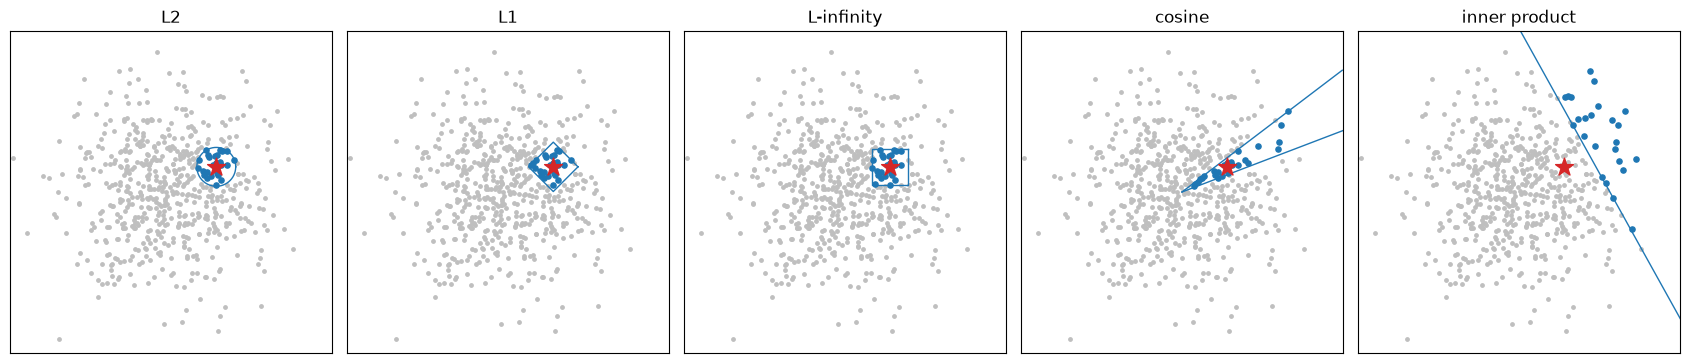

In [2]:
rng = np.random.default_rng(1)
pts = rng.standard_normal((600, 2), dtype=np.float32)
q = np.array([[0.9, 0.5]], dtype=np.float32)
k = 25

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, metric in zip(axes, siann.METRICS):
    res = siann.Index(pts, metric, device="cpu").search(q, k)
    near, kth = res.indices[0], res.scores[0, -1]
    ax.scatter(*pts.T, s=6, c="0.75")
    ax.scatter(*pts[near].T, s=14, c="tab:blue")
    ax.scatter(*q.T, s=180, marker="*", c="tab:red", zorder=3)
    t = np.linspace(0, 2 * np.pi, 400)
    if metric == "l2":
        ax.plot(q[0, 0] + kth * np.cos(t), q[0, 1] + kth * np.sin(t), c="tab:blue", lw=1)
    elif metric == "l1":
        ax.plot(q[0, 0] + kth * np.array([1, 0, -1, 0, 1]), q[0, 1] + kth * np.array([0, 1, 0, -1, 0]), c="tab:blue", lw=1)
    elif metric == "linf":
        ax.plot(q[0, 0] + kth * np.array([1, -1, -1, 1, 1]), q[0, 1] + kth * np.array([1, 1, -1, -1, 1]), c="tab:blue", lw=1)
    elif metric == "cosine":
        a, w = np.arctan2(q[0, 1], q[0, 0]), np.arccos(np.clip(kth, -1, 1))
        for b in (a - w, a + w):
            ax.plot([0, 4 * np.cos(b)], [0, 4 * np.sin(b)], c="tab:blue", lw=1)
    else:   # the line q.x = kth, perpendicular to q
        u = q[0] / np.linalg.norm(q[0])
        base, along = u * kth / np.linalg.norm(q[0]), np.array([-u[1], u[0]])
        ax.plot(*np.array([base - 5 * along, base + 5 * along]).T, c="tab:blue", lw=1)
    ax.set_title({"l2": "L2", "l1": "L1", "linf": "L-infinity", "cosine": "cosine", "ip": "inner product"}[metric])
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## Some vectors

Real embeddings cluster, so instead of uniform noise the rest of the notebook uses 200,000 points in 128
dimensions drawn around 1,000 random centers, and up to 10,000 queries drawn the same way.

In [3]:
centers = rng.standard_normal((1000, 128), dtype=np.float32)


def sample(n):
    return (centers[rng.integers(0, len(centers), n)]
            + 0.3 * rng.standard_normal((n, 128), dtype=np.float32))


xb, xq = sample(200_000), sample(10_000)
xb.shape, xq.shape

((200000, 128), (10000, 128))

## Exact search

`siann.Index(xb, metric)` builds an index, and `index.search(xq, k)` returns each query's `k` nearest base
vectors, best first: `indices` (int64) and `scores`. Without a recall target the search is exact, so these
are the true nearest neighbors.

In [4]:
index = siann.Index(xb, metric="cosine")
res = index.search(xq[:1000], k=5)
res.indices[:3], res.scores[:3]

(array([[141620,  32881,  99292,  30736, 181940],
        [165465, 119464, 126810, 167009, 169820],
        [ 48693,  77403, 184436, 156066, 148656]]),
 array([[0.94919825, 0.9488591 , 0.94846785, 0.94697994, 0.94684327],
        [0.93332636, 0.9314507 , 0.9305315 , 0.9304899 , 0.93022794],
        [0.94368136, 0.94351155, 0.9370097 , 0.93628144, 0.9358636 ]],
       dtype=float32))

`index.plan` says what was chosen and why: here, which device runs the search and how each device would
compute it.

In [5]:
print(index.plan)

siann.Index: 200,000 vectors, 128 dimensions, metric cosine
  kind: exact
  device: gpu
  exact search (no recall target): the results are the true nearest neighbors
  GPU found: exact search on the GPU, measured faster than the CPU in batches (1,000 queries, every metric; 100, L2 and inner product)
  on the CPU: a BLAS matrix multiply through NumPy and siann's Rust top-k
  cosine: vectors normalized to unit length and ranked by inner product


## Scores

Scores are each metric's natural value: the distance for L2 (not squared), L1 and L-infinity, smallest
first, and the similarity for cosine and inner product, largest first. They are exact: here they are
recomputed with NumPy for an L2 search. The metrics also disagree about who is nearest, even on the same
data: the share of each L2 top 10 that another metric's top 10 shares is below.

In [6]:
l2 = siann.Index(xb, "l2").search(xq[:1000], k=10)
print("L2 scores exact:", np.allclose(l2.scores, np.linalg.norm(xb[l2.indices] - xq[:1000, None, :], axis=2), rtol=1e-4))
for metric in ("l1", "linf", "cosine", "ip"):
    other = siann.Index(xb, metric).search(xq[:1000], k=10).indices
    shared = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(l2.indices, other)])
    print(f"{metric:7s} shares {shared:.0%} of L2's top 10")

L2 scores exact: True
l1      shares 68% of L2's top 10
linf    shares 25% of L2's top 10
cosine  shares 82% of L2's top 10
ip      shares 10% of L2's top 10


## The GPU and the CPU, by batch size

`device="cpu"` or `device="gpu"` pins an index to one device, and the same argument to `search` overrides it
for one call; each device makes its own copy of the vectors the first time a search needs it. Both return
the same neighbors. Which is faster depends on the batch and the metric: a GPU call has a fixed cost that a
large batch spreads thin, and L2, cosine and inner product are matrix multiplies on either device, where
L1 and L-infinity have no matrix-multiply form, so the GPU's lead is largest there.

Below, queries per second on this machine at batch sizes from 1 to 10,000, k = 10. Each point is the
second of two identical calls: the first builds the device's copy and, on the GPU, compiles the kernels for
that batch size.

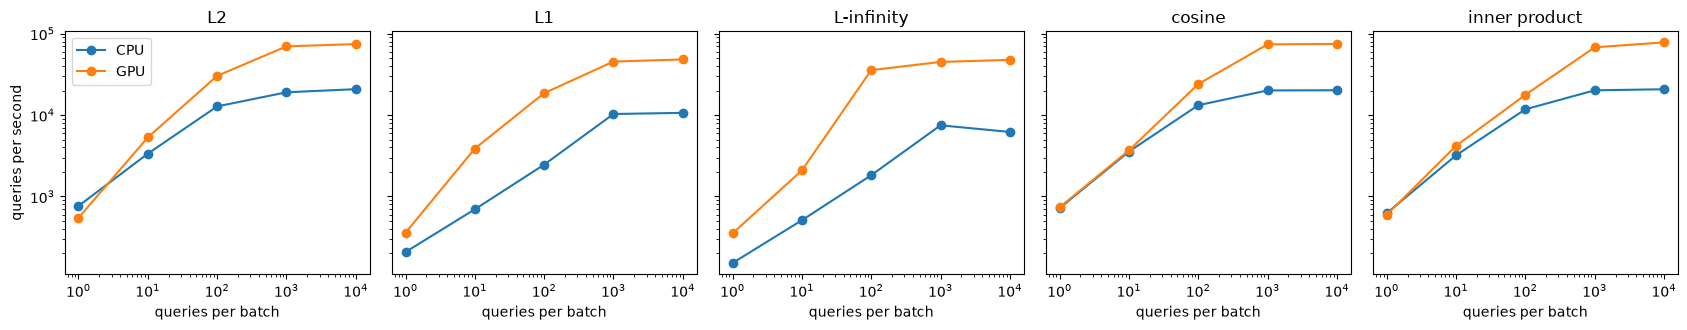

In [7]:
devices = ["cpu", "gpu"] if index.plan.device == "gpu" else ["cpu"]
batches = [1, 10, 100, 1000, 10_000]
rate = {}
for metric in siann.METRICS:
    idx = siann.Index(xb, metric)
    for device in devices:
        for b in batches:
            idx.search(xq[:b], 10, device=device)
            start = time.perf_counter()
            idx.search(xq[:b], 10, device=device)
            rate[metric, device, b] = b / (time.perf_counter() - start)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, metric in zip(axes, siann.METRICS):
    for device in devices:
        ax.plot(batches, [rate[metric, device, b] for b in batches], marker="o", label=device.upper())
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("queries per batch")
    ax.set_title({"l2": "L2", "l1": "L1", "linf": "L-infinity", "cosine": "cosine", "ip": "inner product"}[metric])
axes[0].set_ylabel("queries per second"); axes[0].legend()
fig.tight_layout()

In [8]:
for metric in siann.METRICS:
    print(f"{metric:7s} " + "  ".join(
        f"batch {b:>6,}: {rate[metric, 'gpu', b] / rate[metric, 'cpu', b]:5.1f}x" for b in batches)
          if "gpu" in devices else metric)

l2      batch      1:   0.7x  batch     10:   1.6x  batch    100:   2.4x  batch  1,000:   3.7x  batch 10,000:   3.6x
l1      batch      1:   1.7x  batch     10:   5.6x  batch    100:   7.6x  batch  1,000:   4.4x  batch 10,000:   4.5x
linf    batch      1:   2.3x  batch     10:   4.1x  batch    100:  19.5x  batch  1,000:   6.0x  batch 10,000:   7.7x
cosine  batch      1:   1.0x  batch     10:   1.0x  batch    100:   1.8x  batch  1,000:   3.7x  batch 10,000:   3.7x
ip      batch      1:   1.0x  batch     10:   1.3x  batch    100:   1.5x  batch  1,000:   3.4x  batch 10,000:   3.8x


The table gives the GPU's speed over the CPU's at each batch size; below 1, the CPU is faster. On an
Apple M3 Max, single queries by L2, cosine and inner product run faster on the CPU, the two are about level
at 10 queries, and the GPU leads from about 100; for L1 and L-infinity the GPU leads at every batch size.
`siann.Index` runs exact search on the GPU whenever it finds one, so for single queries by L2, cosine or
inner product, `device="cpu"` is the faster choice.

## Exact search as ground truth

An approximate index is judged by its recall: the share of the true nearest neighbors it finds. That needs
the true neighbors first, for many queries, which exact search on the GPU provides quickly:

In [9]:
truth_index = siann.Index(xb, "l2")
truth_index.search(xq, 10)                         # builds the copy, compiles for this batch
start = time.perf_counter()
truth = truth_index.search(xq, 10).indices
print(f"true 10 nearest neighbors of {len(xq):,} queries among {len(xb):,}: "
      f"{time.perf_counter() - start:.2f} s on the {truth_index.plan.device.upper()}")


def recall(found, truth):
    return np.mean([len(set(a) & set(b)) / truth.shape[1] for a, b in zip(found, truth)])


recall(truth, truth)

true 10 nearest neighbors of 10,000 queries among 200,000: 0.13 s on the GPU


np.float64(1.0)

## When fewer than k exist

Asking for more neighbors than there are vectors returns all of them, then `-1` in the missing slots, with
the metric's worst score (infinity for a distance, minus infinity for a similarity). A neighbor is never
made up.

In [10]:
small = siann.Index(xb[:3], "l2")
small.search(xq[:1], k=5)

SearchResult(indices=array([[ 1,  2,  0, -1, -1]]), scores=array([[15.446124, 16.946627, 17.480204,       inf,       inf]],
      dtype=float32))

## What siann refuses

siann searches dense vectors, so a sparse matrix is refused with an explanation rather than converted
silently; so is a recall target, which asks for approximate search.

In [11]:
import scipy.sparse

for attempt in (lambda: siann.Index(scipy.sparse.random(100, 20, density=0.1, format="csr"), "ip"),
                lambda: siann.Index(xb, "l2", recall=0.95)):
    try:
        attempt()
    except NotImplementedError as e:
        print("NotImplementedError:", e)

NotImplementedError: xb is a sparse matrix: siann searches dense vectors; pass a NumPy array (x.toarray() for a small one)
NotImplementedError: recall targets (approximate search) are not supported in this version: use recall=None for exact search
